# Three-dimensional Bragg coherent crystal strain imaging


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次完善叙述，并将同源执行副本的完整历史输出同步到本规范Notebook；没有重新运行重建。历史结果不是本轮新计算；方法参考不代表独立物理真值。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `bragg_coherent_crystal_strain` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：photon_counts (1, 2, 121, 256, 256) int32：Raw detector photon counts; axes batch, position P1/P2, increasing rocking angle, detector row downward, detector column. Unit: count.；theta (1, 2, 121) float64：Recorded per-frame sample rocking motor angles. Unit: degree.。恢复目标：两位置三维复散射密度及非负归一化coherence核。

获取模型：中心正号DFT的幅度平方经有限卷积、已知peak roll及裁剪形成raw计数。实际恢复算法：solvers.reconstruct/reconstruct_one：ER/HIO、shrinkwrap、显式coherence更新及每位置200 starts ensemble。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

GT/参考情况：数值方法参考，不能当作独立物理真值；baseline为物理方向校正后的方法ensemble；没有独立晶体位移或应变真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：bragg_coherent_crystal_strain.ipynb单元8：5. Results；bragg_coherent_crystal_strain_executed.ipynb单元3有保存图；axis.set_title(f'P{position+1}: {title}', fontsize=9)；bragg_coherent_crystal_strain_executed.ipynb单元8：5. Results；bragg_coherent_crystal_strain_executed.ipynb单元9有保存图；图内容由该单元调用的本地visualization函数生成；bragg_coherent_crystal_strain_executed.ipynb单元10有保存图；图内容由该单元调用的本地visualization函数生成。图/比较代码位于单元3, 5, 9, 10（从0计数）。代码单元7个，已从逐字同源的执行副本同步execution_count 1–7及10幅代码PNG输出；本轮没有重新运行。已核历史日志严格覆盖P1/P2各200 starts（共400），每start 1020更新，CLI约8132秒。

**已同步真实历史全量运行输出：** 7个代码单元的source与执行副本逐字相同，400 starts日志、完整误差/选择记录及非Notebook科学文件hash均与私有历史运行证据匹配。10幅代码图包括两位置实际观测、fresh场/phase/strain/回投影/coherence和完整方法参考比较。P1 source pilot附件单独标注，不计入10幅，也不替代P2或全量结果。本次只同步既有outputs/count，未重新求解。

限制与缺口：canonical现已同步同源完整历史执行输出，原执行副本与审计备份保留。历史Notebook整文件hash因后续Markdown维护不同，不能声称字节等于原始artifact；本轮同步只改变outputs/execution_count及此导航块。**strict fixed-seed selected10 ensemble与public-contract solvability仍未解决，本任务仍排除在可验收候选之外；同步输出不关闭科学验收门槛，也不代表独立物理准确性。**

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Recover the complex crystalline density and a partial-coherence kernel at **both** measured positions of a gold-coated ZnO microrod. Each reconstruction uses the entire 121 x 256 x 256 experimental volume. Density magnitude locates coherently scattering material; its phase measures displacement projected on a single Bragg vector. Phase loss, unknown support, partial coherence and local minima require a substantial nonconvex search.

This notebook actively executes the complete cleaned benchmark: **200 starts per position, 1020 ER/HIO updates per start, all partial-coherence updates and ten-result aligned averaging**. It does not load an archived reconstruction as a fresh result. The unmodified upstream implementation produced nonfinite values in the bound complete run; its failure remains documented in validation, rather than plotted as zero. A separately identified, physically corrected upstream run supplies numerical comparisons, not actual ground truth.


In [1]:
from pathlib import Path
import sys, time, json, subprocess
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
TASK = next(p for p in (Path.cwd(), Path.cwd().parent) if (p/'src/main.py').is_file())
if str(TASK) not in sys.path:
    sys.path.insert(0, str(TASK))
from src.preprocessing import (load_observations, measured_amplitude,
    prepare_observations, real_space_basis, reciprocal_geometry)
from src.visualization import (density_phase_figures, strain_figure,
    observation_figure, coherence_figure, ensemble_error_figure, support_boundary_figure)
counts, theta = load_observations(TASK/'data/raw_data.npz')
REFERENCE = TASK/'notebooks/reference_outputs'
print('Complete real observation shape:', counts.shape, 'counts:', counts.dtype)

review_spec = json.loads((TASK/'evaluation/metrics.json').read_text(encoding='utf8'))
assert review_spec['method_reference_review']['status'] == 'passed'
print('Reference scope:', review_spec['method_reference_review']['scope'])


Complete real observation shape: (2, 121, 256, 256) counts: int32
Reference scope: selected corrected-method reference consistency only; physical truth and paper morphology/absolute strain not certified


## 2. Data

The original measurements are the two real NeXus rocking scans P1/P2 released as Zenodo dataset [7553757](https://doi.org/10.5281/zenodo.7553757), associated with the ZnO strain-imaging study [10.1002/aelm.202100546](https://doi.org/10.1002/aelm.202100546). Public counts and motor angles are value-preserving conversions to NPZ. There is no added noise, synthetic phantom, detector-plane crop or angular downsampling.

The 9 keV beam, 55 micrometer pixels, 2.8 m sample-detector distance and 0.002 degree nominal rocking increment define an oblique grid. Detector angles are 28.488 and 0.0478 degrees. The original distance string was mislabeled with meter units; physical 2.8 m follows the experimental description. Nominal geometry differs slightly from the article's absolute reflection position, so we study **relative projected strain**, without asserting absolute article strain, a full tensor or electric-field recovery.

The selected complete source preprocessing applies explicit auto threshold, square root, even-fast padding from121 to126 rocking planes (two before, three after), and peak centering. The resulting126-grid rolls are P1 `(1,-19,-3)` and P2 `(0,-49,-3)`. This internal noise-suppressed amplitude is distinct from the unchanged public counts; the physical residual still evaluates every original121-plane count. The following panels display both raw acquisitions and the actual prepared inverse inputs.
The calibrated nominal beam dimensions are2000 by450nm (horizontal by vertical), but its complete complex profile is unavailable. The density is probe-weighted; a separated axial lobe cannot by itself establish a reconstruction error. The actual article Figure1c contains a dominant front section and weaker axial lobes at1/e.

Public counts have batch/position/rocking/detector-row/detector-column axes `(1, 2, 121, 256, 256)`; rocking angles and detector geometry calibrate coordinates, while density and coherence are inferred quantities. Photon counts retain their measured scale.


The observations are real photon-count measurements, not simulated objects. The public archive contains the entire detector and angular extents at both positions; no two-dimensional slice or synthetic replacement is used.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| photon_counts | (1, 2, 121, 256, 256) | int32 | Raw detector photon counts; axes batch, position P1/P2, increasing rocking angle, detector row downward, detector column. Unit: count. |
| theta | (1, 2, 121) | float64 | Recorded per-frame sample rocking motor angles. Unit: degree. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Facility and beamline | APS 34-ID-C | none | Synchrotron coherent Bragg diffraction acquisition. |
| Specimen | Gold-coated ZnO microrod | none | Two spatial measurement positions, in stored P1/P2 order. |
| Photon energy | 9 | keV | Nominal incident X-ray photon energy. |
| Nominal focused beam dimensions | 2000 by 450, horizontal by vertical | nm | Experimental beam size after KB focusing and a slit; the full complex illumination field and its exact spatial profile are not calibrated inputs. |
| Wavelength convention | 1.2398419843320026 / 9 | nm | Photon energy-to-wavelength conversion used for the nominal geometry. |
| Detector | Timepix, 256 by 256 | pixel | Full recorded detector plane. |
| Pixel pitch | 55 | micrometer | Square detector pixels. |
| Sample-detector distance | 2.8 | m | Physical distance verified against the experimental description. |
| Exposure | 0.02 | second per frame | Per-frame integration time. |
| Nominal rocking increment | 0.002 | degree | Uniform-grid first-order model; recorded motor angles are also supplied. |
| Scan interval | 23.685004 to 23.925 | degree | Recorded first and last rocking angles. |
| Detector in-plane angle delta | 28.488 | degree | Nominal detector motor angle. |
| Detector out-of-plane angle gamma | 0.0478 | degree | Nominal detector motor angle. |
| Sample chi | 95.4 | degree | Recorded sample-circle position; above the rocking theta circle. |
| Sample phi | 3 | degree | Recorded sample-circle position; above theta. |
| Laboratory frame | outboard, up, downstream | none | Cartesian rows of the nominal reciprocal and real-space bases. |
| Boundary | zero extension for coherence convolution | none | No periodic wrap of coherence convolution. Fourier transform itself is discrete and periodic. |
| Measured peak index, P1 / P2 | (60,147,131) / (61,177,131) | array index | First maximum in stored rocking/row/column order, zero based. |
| Noise | measured counting data; no added synthetic noise | count | No independently calibrated read-noise or background variance is supplied. |

The data originate from the two NeXus files `P1.nxs` and `P2.nxs` in the dataset cited below. Counts and recorded theta arrays retain their original values and dtypes. The source files mistakenly label the distance string `2800` with meter units; the independently documented physical distance is 2.8 m. This correction applies to acquisition metadata, not to measured counts. Only relative strain in the specified geometry is supported by the task.



P1: raw photon sum=7601377, theta interval=[23.685004 23.925   ]
Actual inverse-input shape/threshold/padding/roll: (126, 256, 256) {'intensity_threshold': 2.1296440957926044, 'padding': ((2, 3), (0, 0), (0, 0)), 'peak_shift': array([  1, -19,  -3])}


P2: raw photon sum=6558518, theta interval=[23.685004 23.925   ]
Actual inverse-input shape/threshold/padding/roll: (126, 256, 256) {'intensity_threshold': 2.0, 'padding': ((2, 3), (0, 0), (0, 0)), 'peak_shift': array([  0, -49,  -3])}


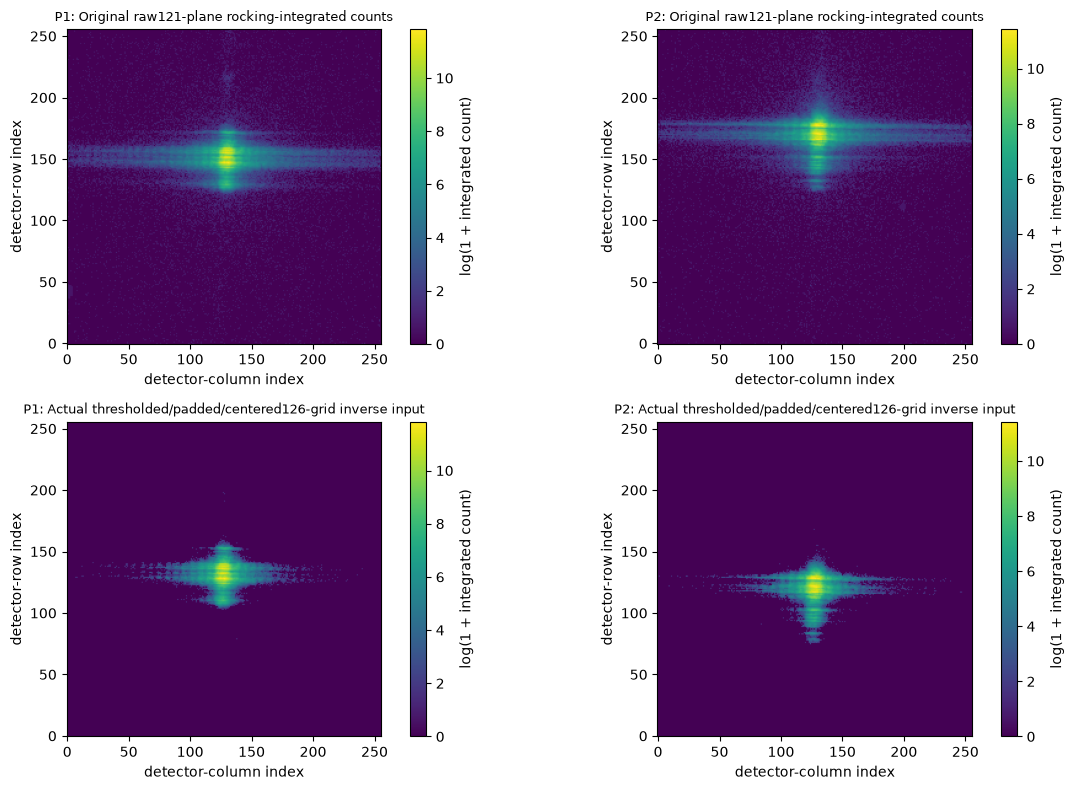

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for position in range(2):
    prepared, metadata = prepare_observations(counts[position])
    panels = (counts[position].astype(float).sum(axis=0),
              (prepared.astype(float)**2).sum(axis=0))
    titles = ('Original raw121-plane rocking-integrated counts',
              'Actual thresholded/padded/centered126-grid inverse input')
    for row, (panel, title) in enumerate(zip(panels, titles)):
        axis = axes[row, position]
        image = axis.imshow(np.log1p(panel), origin='lower', cmap='viridis')
        axis.set_title(f'P{position+1}: {title}', fontsize=9)
        axis.set(xlabel='detector-column index', ylabel='detector-row index')
        fig.colorbar(image, ax=axis, label='log(1 + integrated count)')
    print(f'P{position+1}: raw photon sum={int(counts[position].sum())}, theta interval={theta[position,[0,-1]]}')
    print('Actual inverse-input shape/threshold/padding/roll:', prepared.shape, metadata)
fig.tight_layout()

plt.show()
plt.close(fig)
del prepared, panels


## 3. Physics

For a complex density $x$, the centered positive-sign unscaled transform is


$$
F_+x=C\,\mathrm{ifftn}(C^{-1}x,\mathrm{norm}=\mathrm{forward}),
$$


where $C$ is FFT shift and its inverse is inverse FFT shift, applied to the126 by256 by256 grid. With fixed observation-derived roll $R_s$, unit-mass nonnegative coherence kernel $k$, raw counts $I$, and measurement error $\eta$,


$$
I=Q R_{-s}(|F_+x|^2*k)+\eta.
$$


The star is zero-extended linear three-dimensional convolution, cropped from index $\lfloor(K-1)/2\rfloor$ per kernel axis of length $K$. Here $Q$ extracts rocking indices2:123 after the inverse roll; the fixed shifts are $(1,-19,-3)$ for P1 and $(0,-49,-3)$ for P2. To predict original121-plane coordinates, undo the roll and remove only extra grid planes **after** convolution. This boundary convention prevents replacing the operator with circular convolution or commuting roll with blur.

The phase $\phi=\arg x=q\cdot u$ measures projected displacement, with scattering vector $q$ in rad/nm and displacement $u$ in nm. The reciprocal basis $B$ maps stored frequency indices to laboratory coordinates. The real-space basis is $D=2\pi B^{-T}\operatorname{diag}(1/N)$ in nm/index for shape $N$. Relative projected strain is $q\cdot\nabla\phi/|q|^2$ after a fixed support-interior mean subtraction. Central complex ratios require two-step phase differences below $\pi$; they do not resolve phase wraps beyond that limit. A single reflection cannot recover a full strain tensor.
The output Fourier grid is126 by256 by256. Original121 rocking planes embed with2 extra planes before and3 after. For raw physical comparison, inverse-roll the finite blurred predicted intensity then extract rocking indices2:123; compare every original measured count. Additional planes are a discretization convention, not observations.

With wavelength lambda=1.2398419843320026/9 nm, c=2*pi/lambda, detector angles delta=28.488 degrees and gamma=0.0478 degrees, rocking step dtheta=0.002 degrees converted to radians, pitch p=55000 nm and distance L=2.8e9 nm, the nominal basis and Bragg vector are

$$
B=c\begin{pmatrix}
d\theta(1-\cos\delta\cos\gamma)&(p/L)\sin\delta\sin\gamma&(p/L)\cos\delta\\
0&-(p/L)\cos\gamma&0\\
d\theta\sin\delta\cos\gamma&(p/L)\cos\delta\sin\gamma&-(p/L)\sin\delta
\end{pmatrix},\qquad
q=c\begin{pmatrix}
\cos\gamma\sin\delta\\
\sin\gamma\\
\cos\delta\cos\gamma-1
\end{pmatrix}
$$


Rows are laboratory outboard/up/downstream; columns are rocking/detector-row/detector-column increments in rad/nm. D and q are printed below and checked through B.T@D=2*pi*diag(1/N).


In [3]:
basis = real_space_basis()
B, q = reciprocal_geometry()
print('Oblique real-space basis (nm/index):\n', basis)
print('Nominal scattering vector (rad/nm):', q)
print('Dual sampling check B.T @ D:\n', B.T @ basis)


Oblique real-space basis (nm/index):
 [[ 3.13217429e+01  0.00000000e+00  2.73954889e+01]
 [ 5.47842790e-02 -2.73955079e+01  5.80191090e-03]
 [ 5.77162977e+01  0.00000000e+00 -6.95453401e+00]]
Nominal scattering vector (rad/nm): [21.75460605  0.03805058 -5.52255696]
Dual sampling check B.T @ D:
 [[4.98665501e-02 0.00000000e+00 1.40502807e-19]
 [2.52597123e-22 2.45436926e-02 5.55946315e-22]
 [3.57883523e-18 0.00000000e+00 2.45436926e-02]]


## 4. Method

The cleaned method explicitly implements Fourier amplitude updates, error reduction (ER), hybrid input-output (HIO), shrink-wrap and finite-window coherence estimation. If $z$ is the inverse-transformed amplitude-modified wavefield and $S$ the current support, ER sets $x'=Sz$; HIO sets $x'=z$ inside $S$ and $x'=x-0.9z$ outside. Support is a 0.1-relative threshold of Gaussian-smoothed magnitude, with sigma reduced from 3 to 1 voxels.

Each start performs five repetitions of 20 ER plus 180 HIO, then 20 ER. Partial coherence begins at iteration index 400, updating every 50 steps with 20 multiplicative kernel updates on a central 16-cube. For fixed extrapolated coherent intensity $h$, measured ROI intensity $y$, and finite convolution operator $A_h$, the update is


$$
k\leftarrow k\,\frac{A_h^T(y/\max(A_hk,10^{-30}))}{A_h^T\mathbf 1}.
$$


The exact finite-window transpose includes the even-kernel crop offset; sensitivity cannot be omitted. The normalized kernel is then used in the amplitude-ratio update. This ratio is a heuristic constraint update, not an exact proximal operator. Corrections to original argument direction, transpose crop, sensitivity and Fourier ordering are identified in validation. They are not described as unchanged upstream reproduction.

All 200 starts per position are completed and ranked by final squared relative amplitude error. The source evaluates that error before each amplitude/real-space update; its last error therefore precedes the final ER update and is distinct from a recomputed output residual. The best ten complex objects are aligned by integer translation, constant phase and conjugate inversion, then averaged. Kernels are averaged separately. A scalar derived from public measured amplitude restores physical count scale. No hidden density initializes this reconstruction. The article establishes200 starts, selection and correlation, but does not specify ten results or this exact alignment/mean formula. Those are explicitly selected conventions of the released variant; neither cohere's subpixel GA registration nor its within-run amplitude averaging is claimed as the historical-author ensemble reproduced here.

**Execution cost:** this cell runs the complete benchmark, rather than a preview. The timeout must cover 400 full starts plus contention and I/O; the maintainer nbconvert execution must use `--ExecutePreprocessor.timeout=21600` (six hours per cell). The actual corrected-source P1/P2 all200 timings were5772.13/5054.84 seconds (10826.96 seconds combined), before fresh aggregation, independent Judge and full figure production. Six hours leaves measured headroom for those stages and contention; a7200-second timeout cannot cover the observed acquisition pair. Actual fresh runtime is printed below and must be retained in validation. Generic CuPy primitives preserve the verified upstream GPU precision conventions; no upstream reconstruction package is imported.
The complete extracted preprocessing selects explicit source auto threshold `max(2,.141*mean(nonzero_counts)-3.062)`, clears counts at/below that value, takes float64 square root, pads to the even fast126 grid, peak-centers then stores float32 amplitudes. These are reproducible released-variant settings, not verified historical author parameters. Native final error and ranking use this thresholded126 grid. Final photon scaling uses the same amplitude; the independent physical residual uses all original121 planes without thresholding.

For each incoming density, let w=Fplus(x), let a be the thresholded/centered126-grid measured amplitude and let b=abs(w) before coherence activation or sqrt(max(abs(w)**2*k,0)) afterward. The amplitude-ratio update is wprime=w*(a/b) where b>1e-9 and zero otherwise. The inverse of Fplus maps wprime to z for ER/HIO. Ranking error is sum(abs(b-a)**2)/sum(a**2), evaluated on the incoming object; the native implementation sets the residual to zero wherever b is exactly zero. This error is evaluated before the final ER object update and is separate from the allraw121 output residual.

For each coherence update, u is the current centered16-cube Fourier-amplitude ROI and v is the saved amplitude ROI from the wave constraint at the immediately preceding iteration. Form h=(2*u-v)**2, normalize its total intensity to sum(a_ROI**2), preserving the source square-root/square rounding convention, then perform20 finite-window multiplicative kernel updates with the explicit transpose sensitivity shown above. The nonnegative kernel is normalized to unit sum.

Each returned start is maximum-magnitude normalized. After selecting and aligning10 objects, write their complex mean as m and their normalized mean kernel as kbar. With bbar=sqrt(max(abs(Fplus(m))**2*kbar,0)), restore the amplitude scale alpha=sum(a*bbar)/sum(bbar**2), and save x=alpha*m. This uses public thresholded amplitude; intensity scales by alpha squared. Raw121/Judge predictions use saved x without any posterior scaling. Temporary disk storage contains only objects freshly calculated in this invocation and is removed after aggregation; it changes memory lifetime rather than seed, selection or arithmetic.


In [4]:
begin = time.perf_counter()
command = [sys.executable, '-m', 'src.main', '--device', 'cupy',
           '--measurements', 'notebooks/reference_outputs/fresh_measurements.npz']
fresh_log = TASK/'output/fresh_run.log'
fresh_log.parent.mkdir(exist_ok=True)
with fresh_log.open('w', encoding='utf8') as stream:
    execution = subprocess.run(command, cwd=TASK, stdout=stream, stderr=subprocess.STDOUT, text=True, check=True)
print('\n'.join(fresh_log.read_text(encoding='utf8').splitlines()[-8:]))
fresh_seconds = time.perf_counter()-begin
print('Actual full fresh reconstruction wall time (seconds):', fresh_seconds)
with np.load(TASK/'output/reconstruction.npz', allow_pickle=False) as archive:
    fresh = {key: archive[key] for key in archive.files}
with np.load(REFERENCE/'fresh_measurements.npz', allow_pickle=False) as archive:
    fresh_measurements = {key: archive[key] for key in archive.files}
assert fresh_measurements['errors'].shape == (2,200)
assert fresh['reconstruction'].shape == (1,2,126,256,256)
assert fresh['coherence'].shape == (1,2,16,16,16)


position=2/2 start=194/200 squared_amplitude_error=0.16009284 seconds=20.08
position=2/2 start=195/200 squared_amplitude_error=0.16589262 seconds=19.86
position=2/2 start=196/200 squared_amplitude_error=0.17036361 seconds=19.87
position=2/2 start=197/200 squared_amplitude_error=0.15752984 seconds=20.21
position=2/2 start=198/200 squared_amplitude_error=0.17949414 seconds=19.92
position=2/2 start=199/200 squared_amplitude_error=0.20270104 seconds=19.83
position=2/2 start=200/200 squared_amplitude_error=0.13466965 seconds=19.98
{"seconds": 8131.941464200034, "output": "output\\reconstruction.npz"}
Actual full fresh reconstruction wall time (seconds): 8132.663289099932


## 5. Results

The following figures are computed from the fresh result above. Amplitude, masked phase, nominal relative projected strain, detector consistency and inferred coherence are distinct scientific comparisons. Phase outside weakly scattering material is masked, rather than interpreted as displacement. Axes remain oblique voxel indices; these views are not falsely labeled orthogonal laboratory sections.

The corrected upstream ensemble is loaded only for explicit comparison. It is a validated method reference, **not independent experimental ground truth**. Original unmodified-run failure and the published experimental study remain separate provenance categories.
The independent evaluator reports16 metrics,8 for each position. Complex relative L2 and real conjugate-dot cosine use the same integer translation/conjugate-inversion/global-phase gauge. Kernel relative L2, unit mass and negative mass preserve the declared probability model. Full original121-plane squared amplitude residual uses the saved physical scale without posterior fitting.

Phase RMSE uses the fixed reference1/e support and principal circular phase difference, with pi penalty for a zero predicted voxel. Nominal projected-strain RMSE uses a fixed full3-cube eroded reference support: central index derivatives are half the principal argument of opposite-neighbor complex ratios, laboratory gradient is inverse(D).T times those derivatives, and strain is q dot gradient / dot(q,q). Each field mean is removed independently on that same fixed interior. Phase error is in radians and strain error is dimensionless. These quantify consistency with the independently executed selected method, not true strain or unmodified paper reproduction.


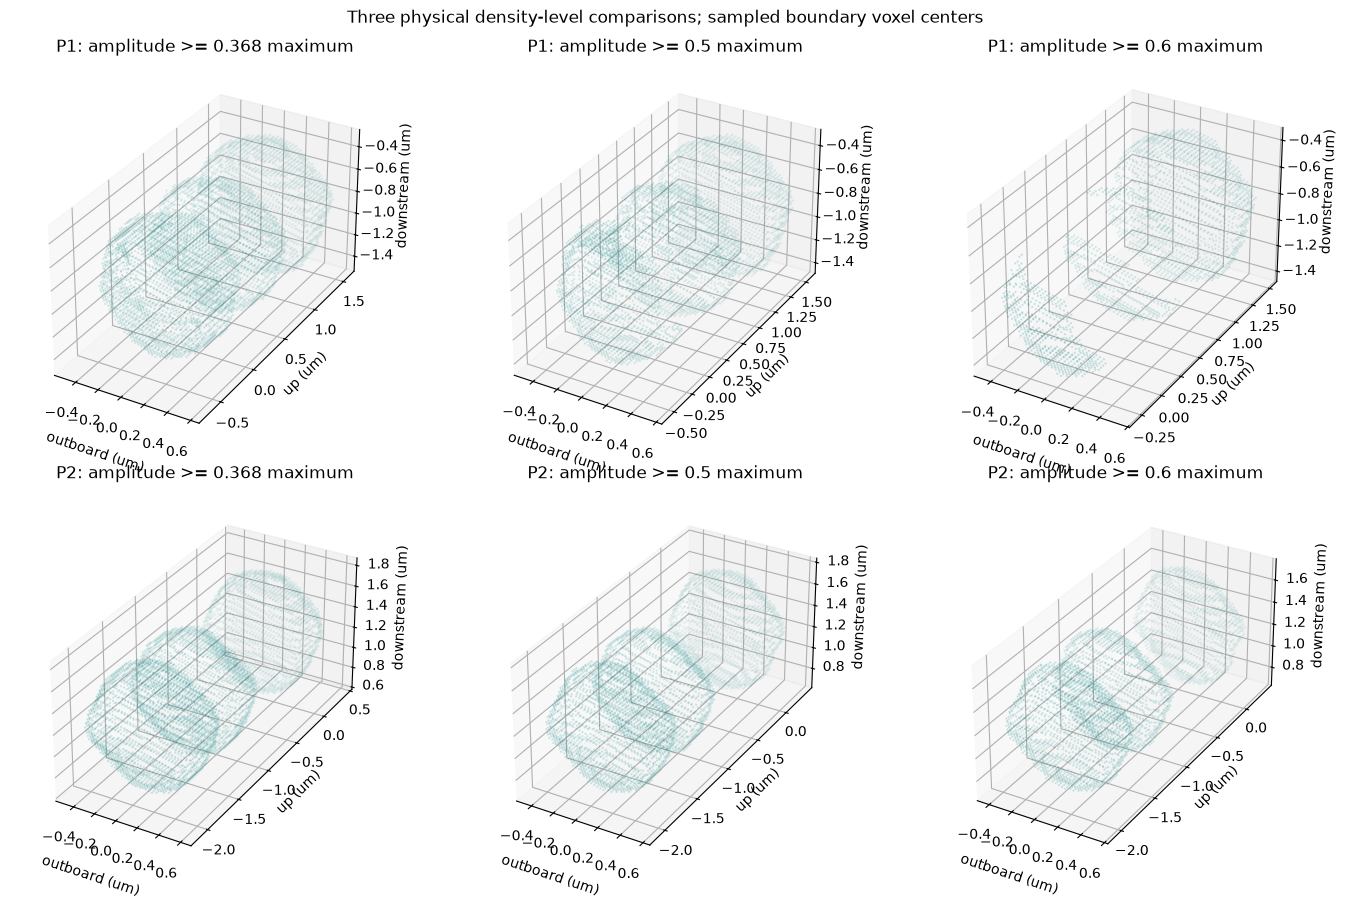

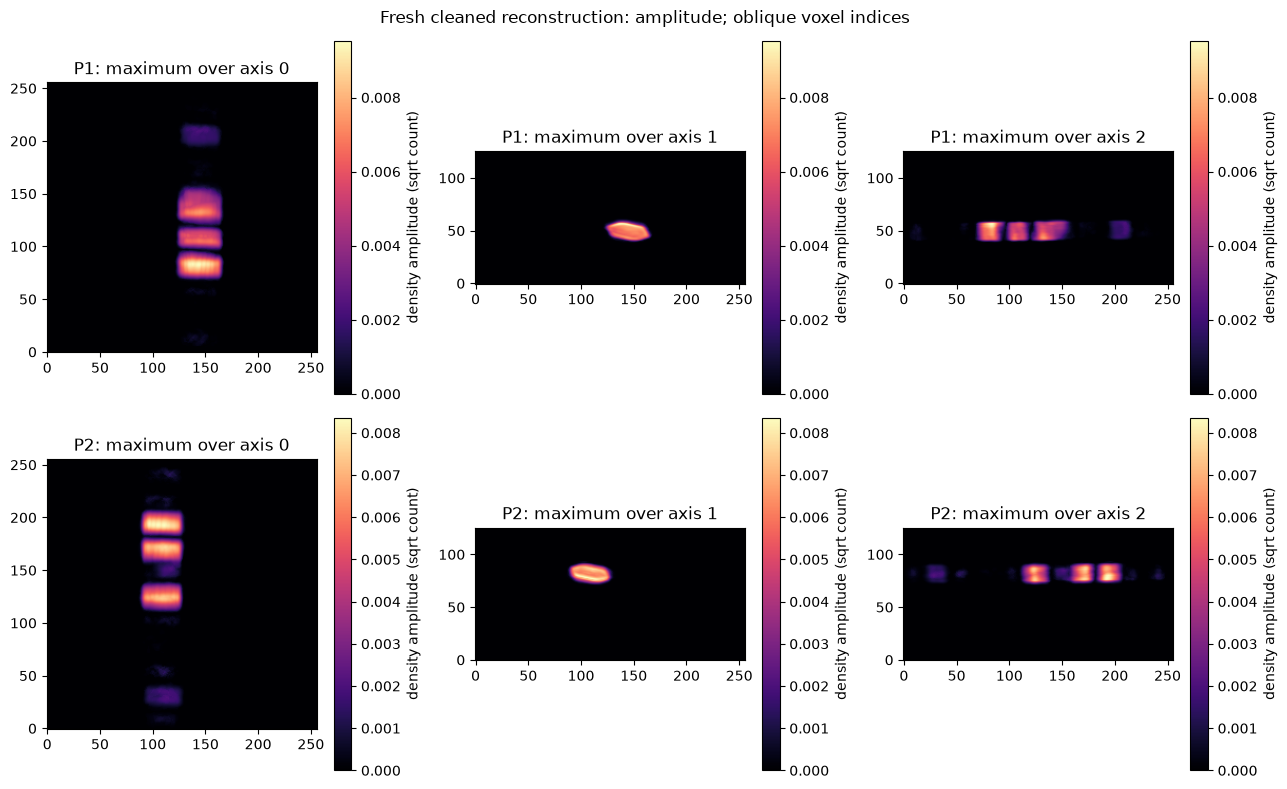

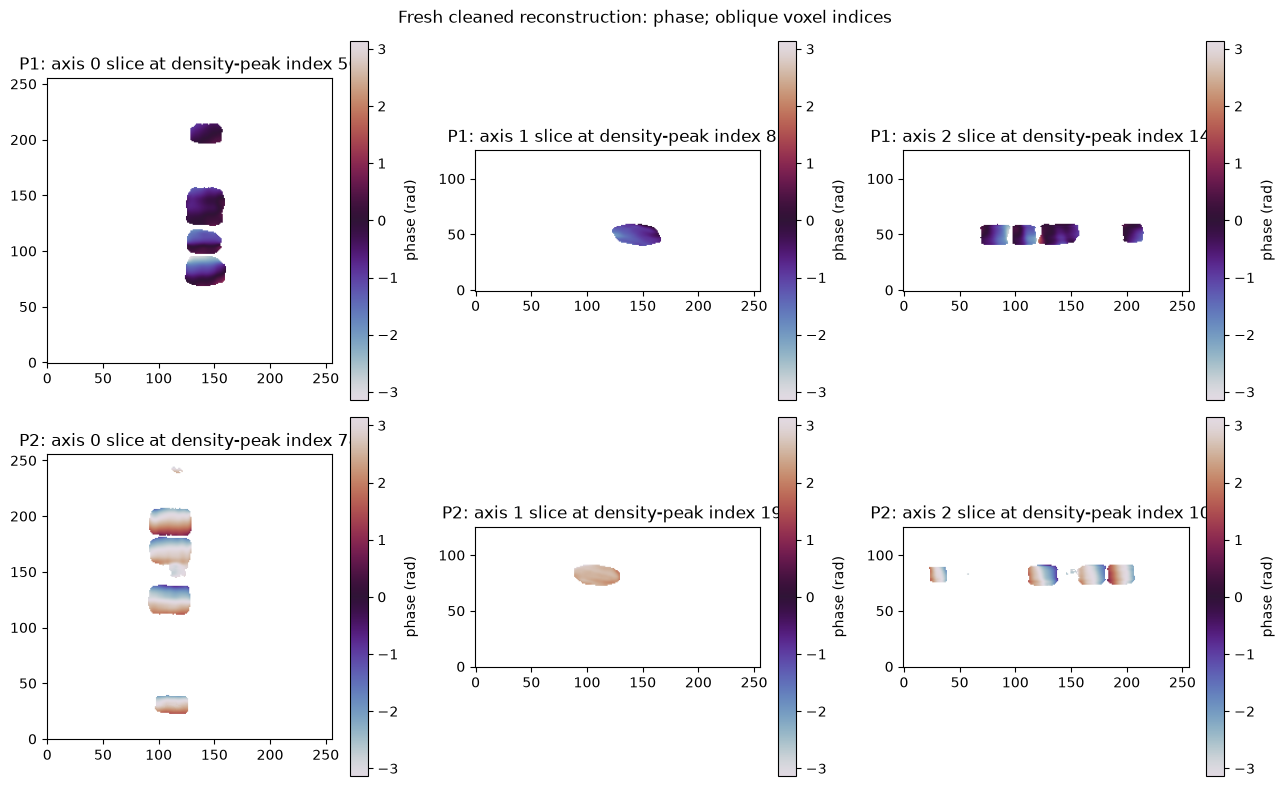

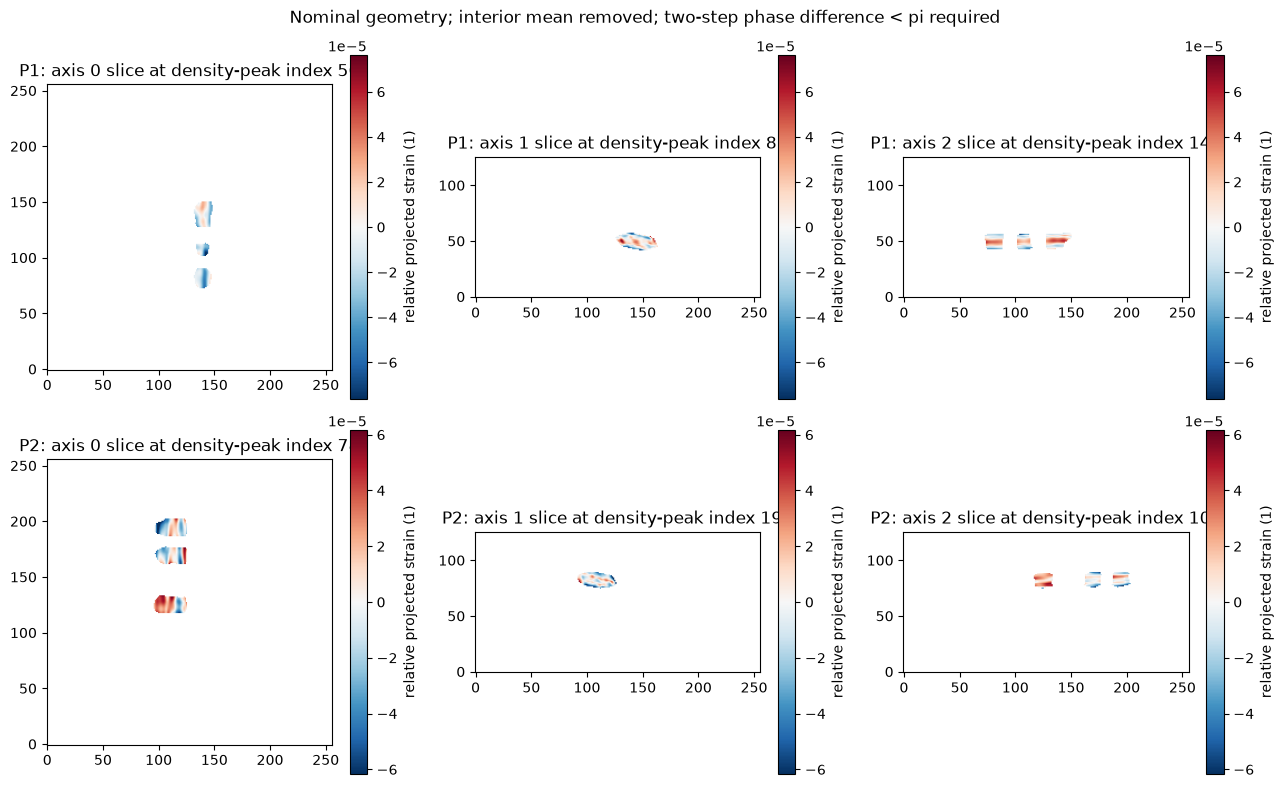

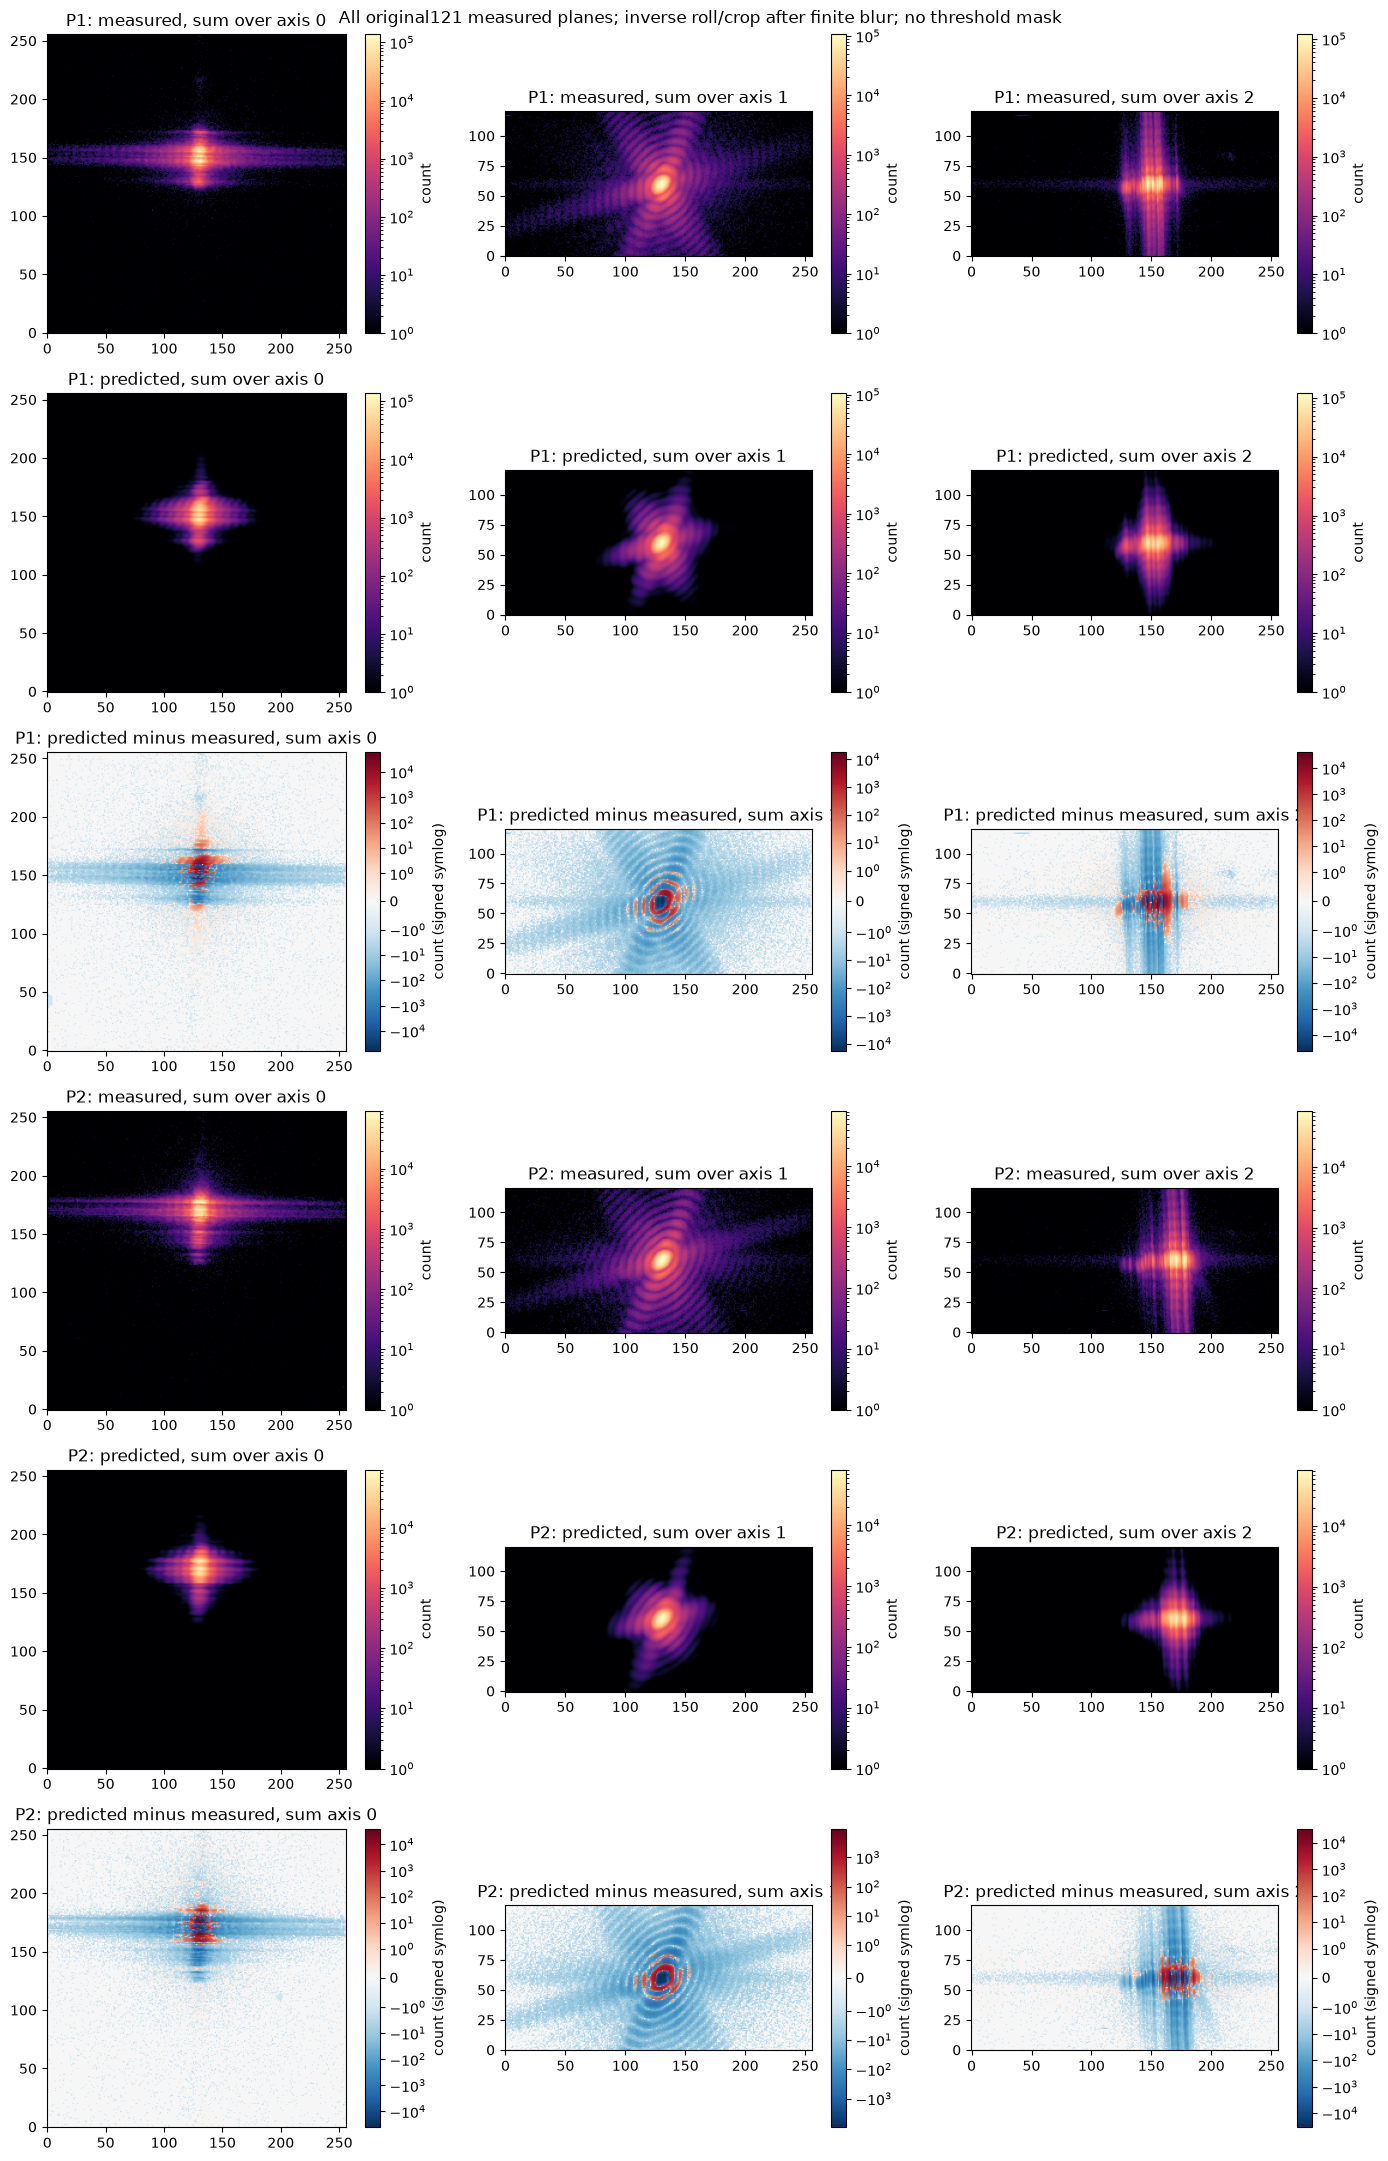

| Fresh position | Measured counts | Predicted counts | Count deficit | Projection relative L2, axes0/1/2 |
| --- | --- | --- | --- | --- |
| P1 | 7601377 | 6848957.8 | 9.89846% | 0.33673178 / 0.13244859 / 0.32182758 |
| P2 | 6558518 | 5828789.8 | 11.12642% | 0.34451475 / 0.11971756 / 0.32280523 |

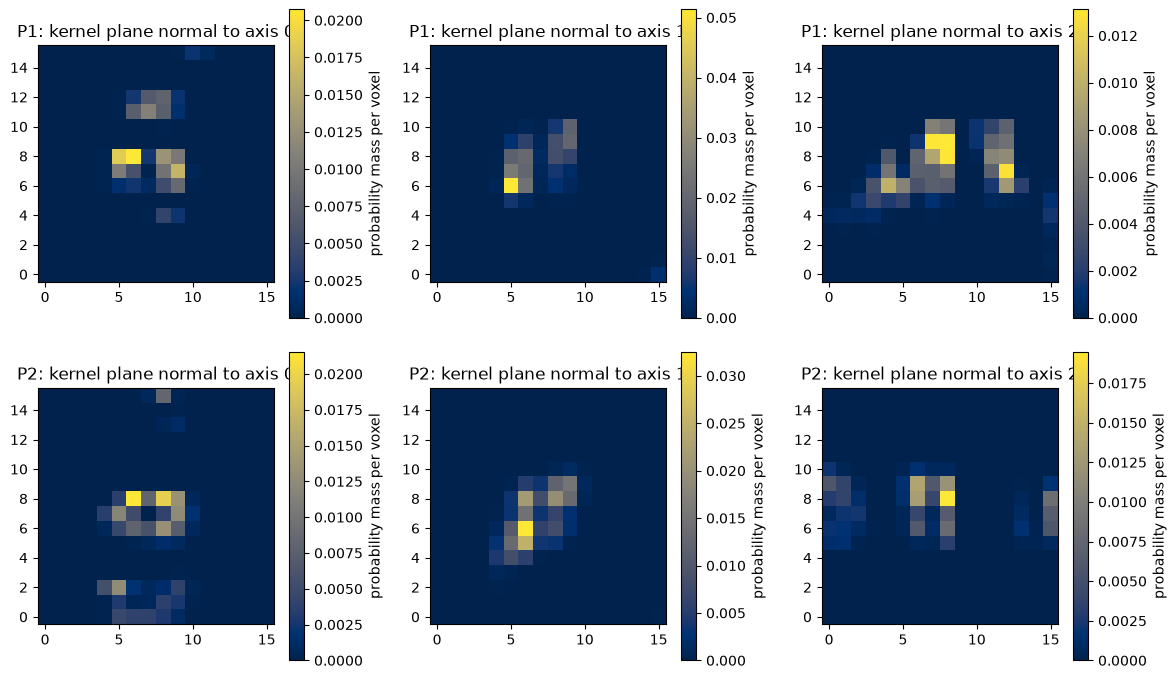

In [5]:
# Require documented selected-method reference review; this does not certify physical truth.
reviewed = json.loads((TASK/'evaluation/metrics.json').read_text(encoding='utf8'))
assert reviewed['method_reference_review']['status'] == 'passed'
assert all(path.is_file() for path in [REFERENCE/'upstream_measurements.npz', TASK/'evaluation/baseline_reference.npz'])
with np.load(REFERENCE/'upstream_measurements.npz', allow_pickle=False) as reviewed_measurements:
    assert reviewed_measurements['errors'].shape == (2,200)
    assert reviewed_measurements['selected'].shape == (2,10)

support_boundary_figure(fresh['reconstruction']); plt.show(); plt.close('all')
figures = density_phase_figures(fresh['reconstruction'])
plt.show(); plt.close('all')
strain_figure(fresh['reconstruction']); plt.show(); plt.close('all')
observation_figure(fresh['reconstruction'], fresh['coherence'], counts); plt.show(); plt.close('all')
from src.physics_model import raw_observation_intensity
count_rows = ['| Fresh position | Measured counts | Predicted counts | Count deficit | Projection relative L2, axes0/1/2 |',
              '| --- | --- | --- | --- | --- |']
for position in range(2):
    _, metadata = prepare_observations(counts[position])
    prediction = raw_observation_intensity(fresh['reconstruction'][0,position],
        fresh['coherence'][0,position], metadata['peak_shift'], metadata['padding'])
    observed = counts[position].astype(np.float64)
    projected_l2 = [np.linalg.norm((prediction-observed).sum(axis=axis)) /
                    np.linalg.norm(observed.sum(axis=axis)) for axis in range(3)]
    measured_total, predicted_total = float(observed.sum()), float(prediction.sum())
    deficit = 1-predicted_total/measured_total
    values = ' / '.join(f'{value:.8f}' for value in projected_l2)
    count_rows.append(f'| P{position+1} | {measured_total:.8g} | {predicted_total:.8g} | {100*deficit:.5f}% | {values} |')
display(Markdown('\n'.join(count_rows)))
coherence_figure(fresh['coherence']); plt.show(); plt.close('all')

del prediction, observed


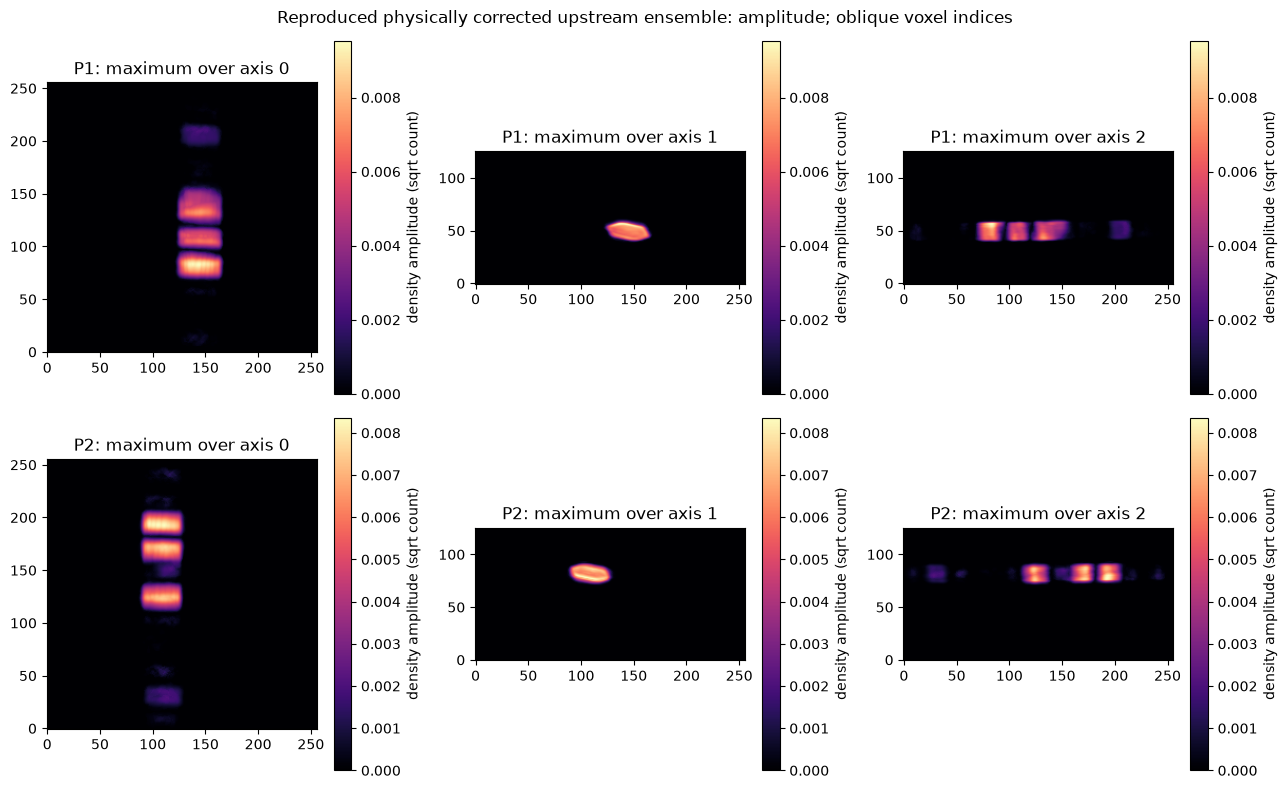

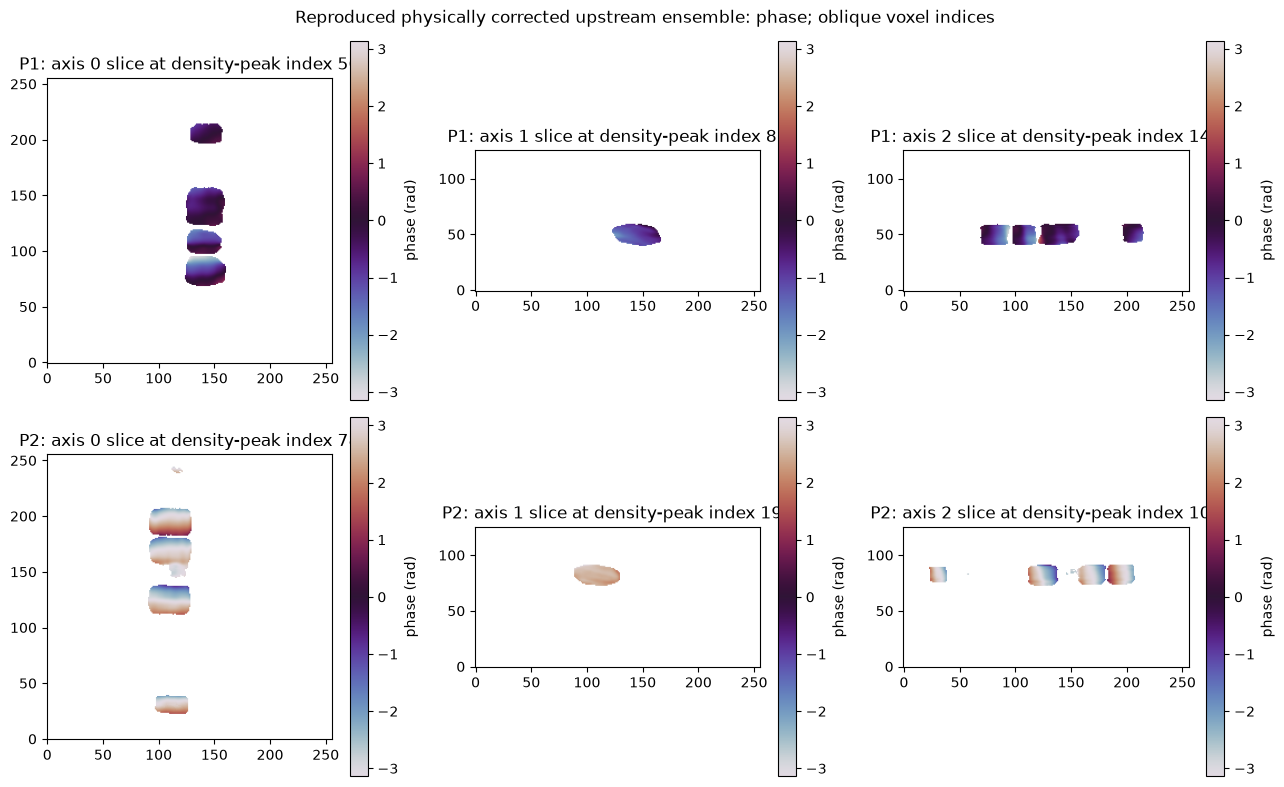

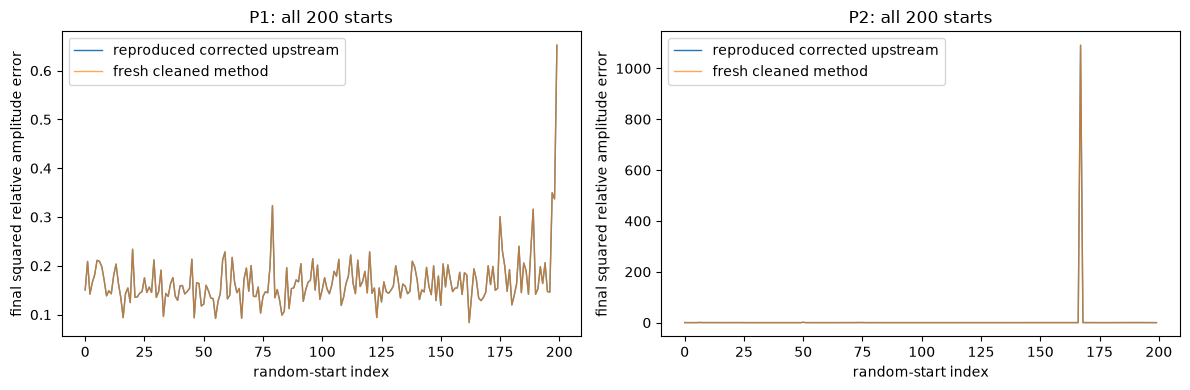

In [6]:
with np.load(TASK/'evaluation/baseline_reference.npz', allow_pickle=False) as archive:
    upstream = {key: archive[key] for key in archive.files}
with np.load(REFERENCE/'upstream_measurements.npz', allow_pickle=False) as archive:
    upstream_measurements = {key: archive[key] for key in archive.files}
density_phase_figures(upstream['reconstruction'], label='Reproduced physically corrected upstream ensemble')
plt.show(); plt.close('all')
ensemble_error_figure(upstream_measurements['errors'], fresh_measurements['errors']); plt.show(); plt.close('all')

del upstream


In [7]:
judge_command = [sys.executable, 'evaluation/judge.py', '--prediction',
    'output/reconstruction.npz', '--report', 'output/judge_report.json']
judged = subprocess.run(judge_command, cwd=TASK, capture_output=True, text=True)
report = json.loads((TASK/'output/judge_report.json').read_text(encoding='utf8'))
assert len(report['metrics']) == 16, report
rows = ['| Metric | Fresh measurement | Acceptance boundary |', '| --- | --- | --- |']
for name, value in report['metrics'].items():
    rule = report['thresholds'][name]
    rows.append(f"| {name} | {value:.10g} | {rule['comparison']} {rule['boundary']:.10g} |")
display(Markdown('\n'.join(rows)))
print('Standalone evaluator:', report['status'], report['errors'])
assert judged.returncode == 0 and report['passed'], report


| Metric | Fresh measurement | Acceptance boundary |
| --- | --- | --- |
| p1_complex_relative_l2 | 1.18468603e-16 | <= 1e-06 |
| p1_complex_cosine | 1 | >= 0.999999999 |
| p1_kernel_relative_l2 | 0 | <= 1e-06 |
| p1_kernel_mass_error | 0 | <= 1e-12 |
| p1_kernel_negative_mass | -0 | <= 0 |
| p1_phase_rmse | 5.903931837e-17 | <= 0.0001 |
| p1_relative_projected_strain_rmse | 6.475103231e-20 | <= 1e-08 |
| p1_raw_amplitude_residual | 0.083327729 | <= 0.083328729 |
| p2_complex_relative_l2 | 1.086568516e-16 | <= 1e-06 |
| p2_complex_cosine | 1 | >= 0.999999999 |
| p2_kernel_relative_l2 | 0 | <= 1e-06 |
| p2_kernel_mass_error | 0 | <= 1e-12 |
| p2_kernel_negative_mass | -0 | <= 0 |
| p2_phase_rmse | 5.593153621e-17 | <= 0.0001 |
| p2_relative_projected_strain_rmse | 5.94539478e-20 | <= 1e-08 |
| p2_raw_amplitude_residual | 0.0960877957 | <= 0.0960887957 |

Standalone evaluator: pass []


### Prior independent corrected-source P1 pilot, not fresh-code output

This inspected comparison comes from the completed independent 200-start P1 source pilot on the exact full observations. It precedes the fresh two-position run above. All 121 original rocking planes are retained after declared inverse shift and padding removal; there is no fitted display scale or background correction. The prediction contains 6,848,957.84 counts versus 7,601,377 measured (9.90% deficit). Count-projection relative L2 errors over axes 0/1/2 are 0.33673178 / 0.13244859 / 0.32182758; full-volume squared amplitude residual is 0.0833277290. Central peaks and rings are recovered, while extended weak tails and alternating central-ring residuals remain clear. Ranking uses thresholded 126-grid pre-final-update error; this physical comparison uses all original121 raw counts and recomputes the returned-object forward prediction. These are distinct criteria.

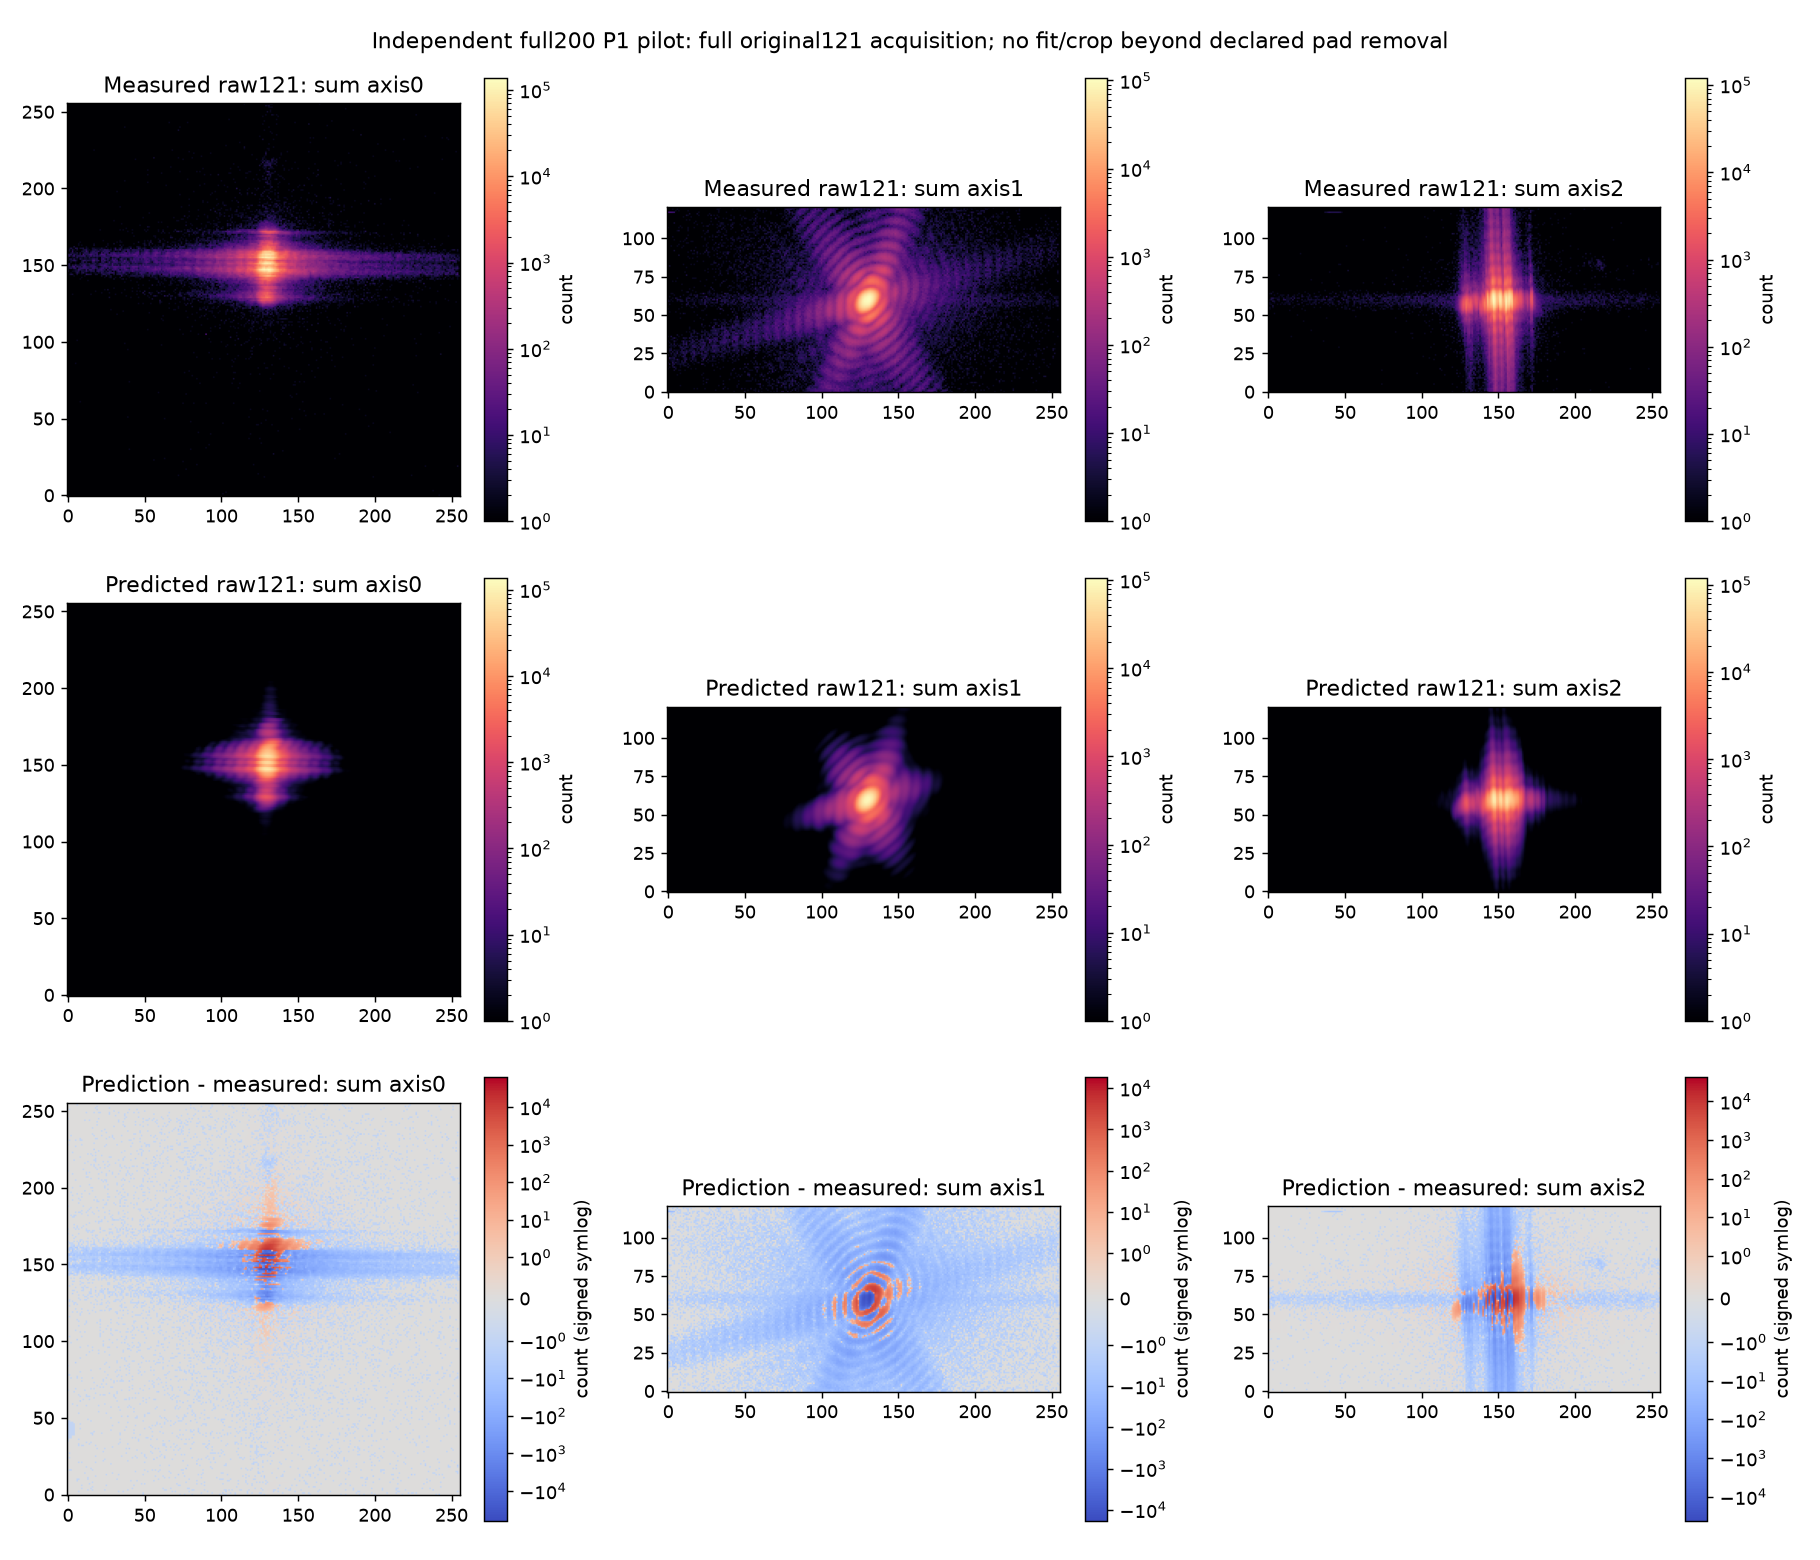


## 6. Conclusion

This review executes the entire published-scale multi-start reconstruction on both real three-dimensional acquisitions, displays freshly computed scientific fields and tests the declared submission through an independent evaluator. Agreement with the corrected method establishes numerical reproduction and observation consistency; it does not establish absolute physical truth. The unmodified implementation's nonfinite result is retained as a failure, not silently substituted.

The valid physical interpretation is coherently scattering density and relative projected strain in the stated nominal geometry. Finite coherence, support uncertainty, phase-wrap assumptions, the selected reflection and nonconvex ambiguity limit stronger claims. Completion additionally requires the independent parity and physics tests, reference-quality review and provenance gates recorded in `test/validation.md`; a notebook title or cached comparison cannot replace them.

The selected ten-result integer/twin/global-phase complex average is a benchmark postprocessing convention; inaccessible historical selection/alignment details prevent claiming exact author ensemble reproduction. Structured raw-count residuals, missing weak diffraction tails, stronger secondary density lobes and a multi-peaked coherence estimate must remain visible in review. Consistency with this numerical reference does not certify the published morphology, absolute strain, probe phase or refraction correction. The three-direction raw-count plots use common measured/predicted log scales and signed residuals without a fitted display scale.
